# 🧠 ABIDE ASD Classification Pipeline
## Phân loại Autism Spectrum Disorder từ rs-fMRI (Standard Literature Pipeline)

---

**Pipeline tổng quan:**
```
ABIDE I (rs-fMRI)
    ↓ CPAC Preprocessed
ROI Time Series (CC200 Atlas — 200 ROIs)
    ↓ Pearson Correlation
Functional Connectivity Matrix (200×200)
    ↓ Upper Triangle → Feature Vector (19,900 features)
SVM (Linear Kernel)
    ↓ 5-Fold Stratified CV
Classification: ASD vs TD
```

**Dataset:** ABIDE I — 539 ASD + 573 TD, 17 sites  
**Atlas:** CC200 (Craddock 200 ROI — Functional Clustering)  
**Model:** Linear SVM (chuẩn mực trong literature ABIDE)  

---
## 📦 Cell 1 — Cài đặt thư viện & Import

In [1]:
# Cài thư viện (chỉ cần chạy lần đầu)
# !pip install nilearn scikit-learn numpy pandas matplotlib seaborn

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# nilearn — xử lý dữ liệu fMRI
from nilearn.datasets import fetch_abide_pcp
from nilearn.connectome import ConnectivityMeasure
from nilearn import plotting

# scikit-learn — machine learning
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import (
    StratifiedKFold, cross_validate, train_test_split
)
from sklearn.metrics import (
    accuracy_score, roc_auc_score, f1_score,
    classification_report, confusion_matrix,
    roc_curve, ConfusionMatrixDisplay
)

# Cấu hình style đồ thị
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.size']  = 11
sns.set_style('whitegrid')
COLORS = {'ASD': '#E74C3C', 'TD': '#3498DB'}

print('✅ Import thành công!')
print(f'   NumPy   : {np.__version__}')
import sklearn; print(f'   Sklearn : {sklearn.__version__}')
import nilearn; print(f'   Nilearn : {nilearn.__version__}')

✅ Import thành công!
   NumPy   : 2.5.3
   Sklearn : 1.9.1
   Nilearn : 0.14.1


---
## 📥 Cell 2 — Tải dữ liệu ABIDE I

**Giải thích:**
- `pipeline='cpac'` → dùng preprocessing của CPAC (chuẩn mực cho ABIDE)
- `band_pass_filtering=True` → đã lọc nhiễu tần số cao/thấp (0.01–0.1 Hz)
- `global_signal_regression=False` → không dùng GSR (còn tranh cãi trong literature)
- `derivatives=['rois_cc200']` → lấy time series đã trích xuất theo Atlas CC200 (200 ROIs)
- `quality_checked=True` → chỉ lấy subjects đã qua kiểm tra chất lượng

> ⏳ **Lần đầu chạy:** Download từ internet, mất 5–30 phút tùy tốc độ mạng.  
> ✅ **Lần sau:** Load từ cache local, chỉ mất vài giây.

In [2]:
print('Đang tải dữ liệu ABIDE I từ server...')

abide = fetch_abide_pcp(
    data_dir='../data',
    pipeline='cpac',
    band_pass_filtering=True,
    global_signal_regression=False,
    derivatives=['rois_cc200'],
    quality_checked=True
)

# Lấy thông tin cơ bản
pheno      = abide.phenotypic              # Bảng thông tin lâm sàng
time_series = abide.rois_cc200            # List time series: mỗi phần tử (T × 200)

# Labels: 1=ASD, 2=TD → đổi về 1=ASD, 0=TD
y_raw  = pheno['DX_GROUP'].values
y      = (y_raw == 1).astype(int)
sites  = pheno['SITE_ID'].values

print(f'✅ Tải thành công!')
print(f'   Tổng số subjects  : {len(y)}')
print(f'   ASD (nhãn=1)      : {y.sum()}')
print(f'   TD  (nhãn=0)      : {(y==0).sum()}')
print(f'   Số sites          : {len(np.unique(sites))}')
print(f'   Số ROI (CC200)    : {time_series[0].shape[1]}')
print(f'\nVí dụ shape 1 subject: {time_series[0].shape}')
print(f'   → {time_series[0].shape[0]} timepoints × {time_series[0].shape[1]} ROIs')

Đang tải dữ liệu ABIDE I từ server...
[fetch_abide_pcp] Dataset directory found: ..\data\ABIDE_pcp
✅ Tải thành công!
   Tổng số subjects  : 871
   ASD (nhãn=1)      : 403
   TD  (nhãn=0)      : 468
   Số sites          : 20
   Số ROI (CC200)    : 200

Ví dụ shape 1 subject: (196, 200)
   → 196 timepoints × 200 ROIs


---
## 📊 Cell 3 — Khám phá Phenotypic Data (Thông tin lâm sàng)

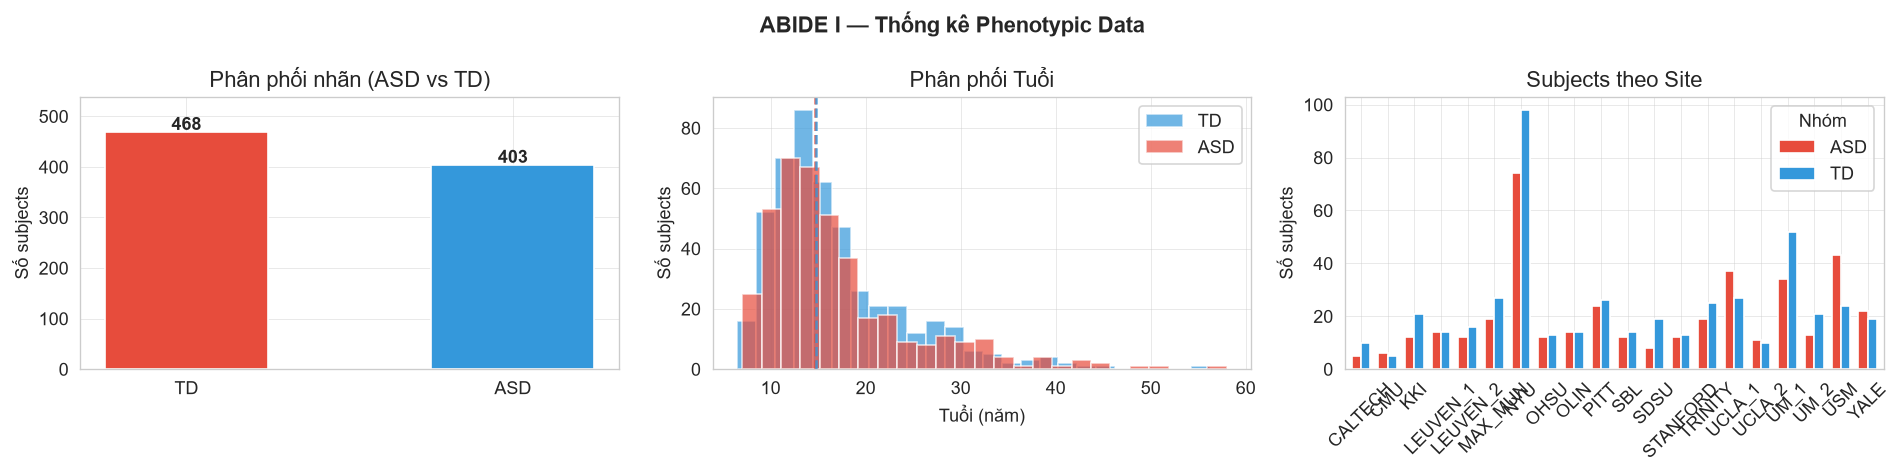

✅ Lưu: 01_phenotypic_overview.png

--- Thống kê tuổi ---
ASD: Mean=17.1, Std=8.0, [Min=7, Max=58]
TD : Mean=16.8,  Std=7.2,  [Min=6,  Max=56]


In [3]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
fig.suptitle('ABIDE I — Thống kê Phenotypic Data', fontsize=13, fontweight='bold')

# ── [1] Phân phối nhãn ASD / TD ──
counts = pd.Series(y).map({1: 'ASD', 0: 'TD'}).value_counts()
bars = axes[0].bar(counts.index, counts.values,
                   color=[COLORS['ASD'], COLORS['TD']], width=0.5, edgecolor='white')
for bar, val in zip(bars, counts.values):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 5,
                 str(val), ha='center', fontweight='bold')
axes[0].set_title('Phân phối nhãn (ASD vs TD)')
axes[0].set_ylabel('Số subjects')
axes[0].set_ylim(0, max(counts.values) * 1.15)

# ── [2] Phân phối tuổi ──
ages_asd = pheno[pheno['DX_GROUP'] == 1]['AGE_AT_SCAN'].dropna()
ages_td  = pheno[pheno['DX_GROUP'] == 2]['AGE_AT_SCAN'].dropna()
axes[1].hist(ages_td,  bins=25, alpha=0.7, color=COLORS['TD'],  label='TD',  edgecolor='white')
axes[1].hist(ages_asd, bins=25, alpha=0.7, color=COLORS['ASD'], label='ASD', edgecolor='white')
axes[1].set_title('Phân phối Tuổi')
axes[1].set_xlabel('Tuổi (năm)')
axes[1].set_ylabel('Số subjects')
axes[1].legend()
axes[1].axvline(ages_asd.median(), color=COLORS['ASD'], linestyle='--', alpha=0.8,
                label=f'Median ASD: {ages_asd.median():.1f}')
axes[1].axvline(ages_td.median(),  color=COLORS['TD'],  linestyle='--', alpha=0.8)

# ── [3] Số subjects theo site ──
site_df = pd.DataFrame({'site': sites, 'label': pd.Series(y).map({1:'ASD', 0:'TD'})})
site_counts = site_df.groupby(['site','label']).size().unstack(fill_value=0)
site_counts.plot(kind='bar', ax=axes[2], color=[COLORS['ASD'], COLORS['TD']],
                 edgecolor='white', width=0.7)
axes[2].set_title('Subjects theo Site')
axes[2].set_xlabel('')
axes[2].set_ylabel('Số subjects')
axes[2].tick_params(axis='x', rotation=45)
axes[2].legend(title='Nhóm')

plt.tight_layout()
plt.savefig('01_phenotypic_overview.png', bbox_inches='tight')
plt.show()
print('✅ Lưu: 01_phenotypic_overview.png')

# Thống kê mô tả
print('\n--- Thống kê tuổi ---')
print(f'ASD: Mean={ages_asd.mean():.1f}, Std={ages_asd.std():.1f}, [Min={ages_asd.min():.0f}, Max={ages_asd.max():.0f}]')
print(f'TD : Mean={ages_td.mean():.1f},  Std={ages_td.std():.1f},  [Min={ages_td.min():.0f},  Max={ages_td.max():.0f}]')

---
## 📈 Cell 4 — Khám phá ROI Time Series (Tín hiệu BOLD)

**Giải thích:**  
Mỗi subject có một ma trận `(T × 200)` — T timepoints, 200 ROI. Mỗi hàng là "ảnh chụp" toàn bộ não tại một thời điểm. Mỗi cột là tín hiệu BOLD của một vùng não theo thời gian.

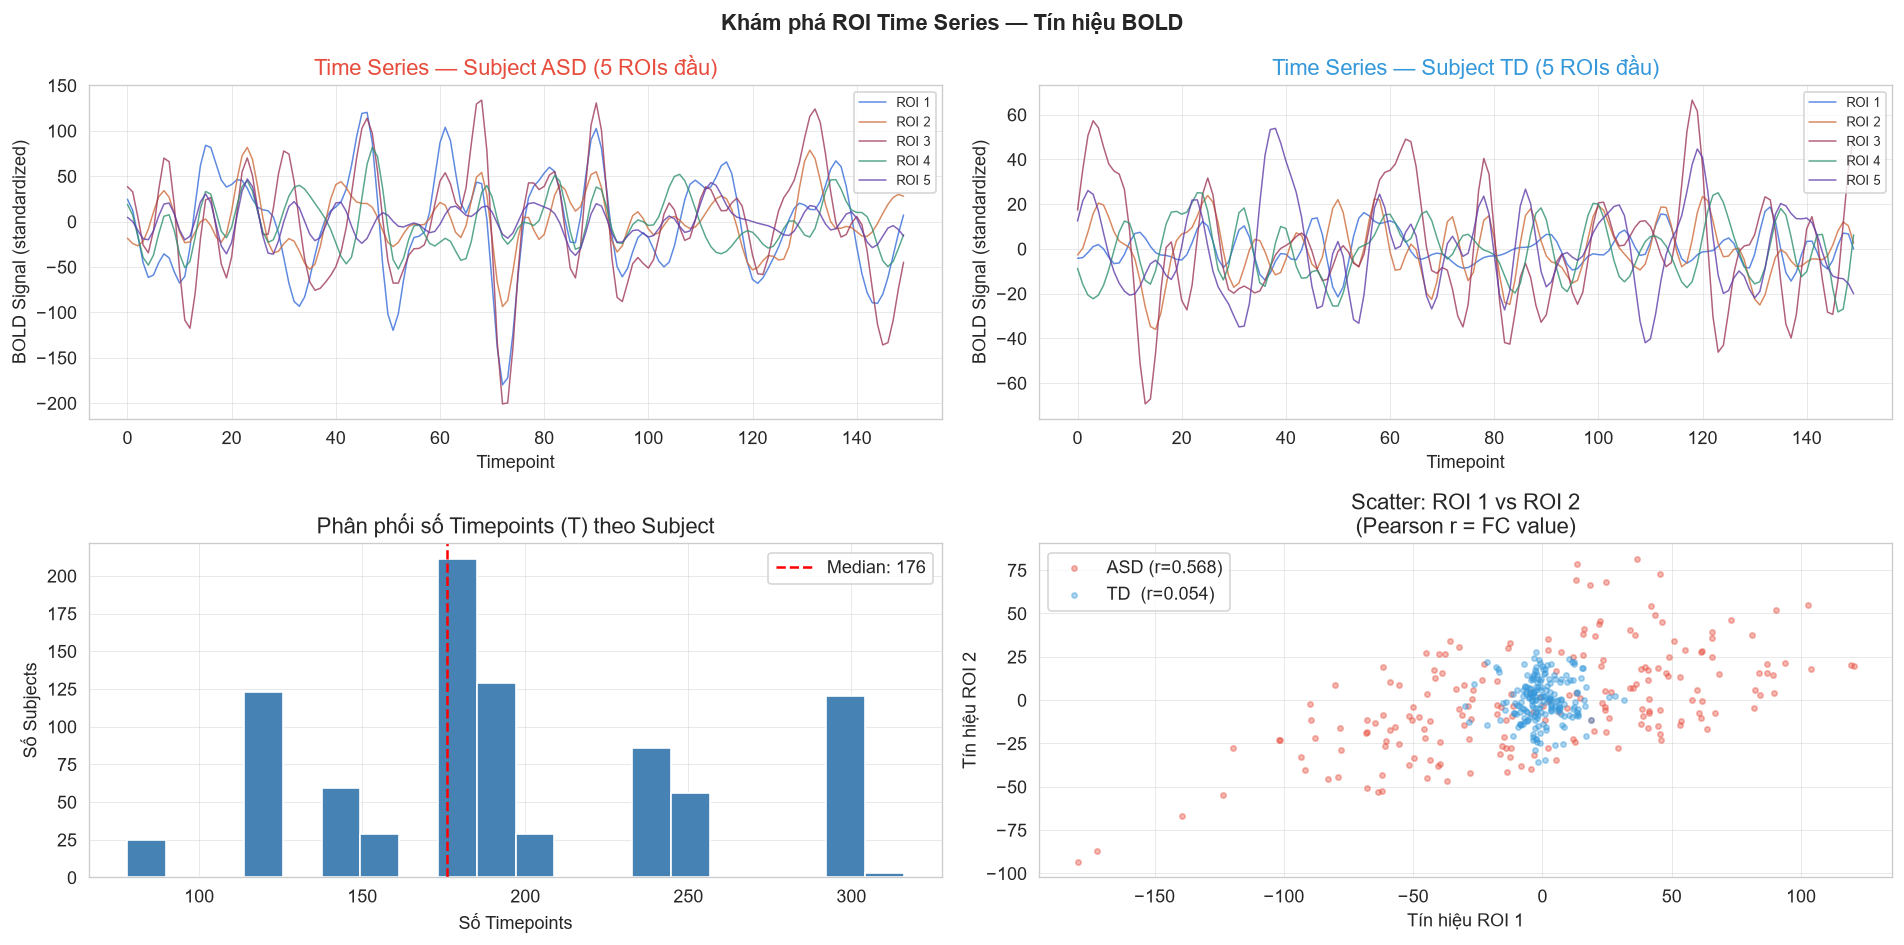

✅ Lưu: 02_bold_timeseries.png

Thông tin timepoints:
  Min: 78, Max: 316, Median: 176
  → Số timepoints khác nhau vì mỗi site có scanner protocol khác nhau (đây là multisite heterogeneity)


In [4]:
# Lấy 1 subject ASD và 1 subject TD để so sánh
idx_asd = np.where(y == 1)[0][0]   # index của subject ASD đầu tiên
idx_td  = np.where(y == 0)[0][0]   # index của subject TD đầu tiên

ts_asd = time_series[idx_asd]   # (T, 200)
ts_td  = time_series[idx_td]    # (T, 200)

n_rois_show = 5   # số ROI hiển thị

fig, axes = plt.subplots(2, 2, figsize=(16, 8))
fig.suptitle('Khám phá ROI Time Series — Tín hiệu BOLD', fontsize=13, fontweight='bold')

# ── [Top-left] Time series của 5 ROI cho subject ASD ──
T_asd = min(ts_asd.shape[0], 150)   # hiển thị tối đa 150 timepoints
for i in range(n_rois_show):
    axes[0,0].plot(ts_asd[:T_asd, i], alpha=0.8, linewidth=0.9,
                   label=f'ROI {i+1}')
axes[0,0].set_title(f'Time Series — Subject ASD (5 ROIs đầu)', color=COLORS['ASD'])
axes[0,0].set_xlabel('Timepoint')
axes[0,0].set_ylabel('BOLD Signal (standardized)')
axes[0,0].legend(fontsize=8, loc='upper right')

# ── [Top-right] Time series của 5 ROI cho subject TD ──
T_td = min(ts_td.shape[0], 150)
for i in range(n_rois_show):
    axes[0,1].plot(ts_td[:T_td, i], alpha=0.8, linewidth=0.9,
                   label=f'ROI {i+1}')
axes[0,1].set_title(f'Time Series — Subject TD (5 ROIs đầu)', color=COLORS['TD'])
axes[0,1].set_xlabel('Timepoint')
axes[0,1].set_ylabel('BOLD Signal (standardized)')
axes[0,1].legend(fontsize=8, loc='upper right')

# ── [Bottom-left] Phân phối số timepoints ──
n_timepoints = [ts.shape[0] for ts in time_series]
axes[1,0].hist(n_timepoints, bins=20, color='steelblue', edgecolor='white')
axes[1,0].set_title('Phân phối số Timepoints (T) theo Subject')
axes[1,0].set_xlabel('Số Timepoints')
axes[1,0].set_ylabel('Số Subjects')
axes[1,0].axvline(np.median(n_timepoints), color='red', linestyle='--',
                  label=f'Median: {np.median(n_timepoints):.0f}')
axes[1,0].legend()

# ── [Bottom-right] Correlation giữa 2 ROI cụ thể (ASD vs TD) ──
roi_a, roi_b = 0, 1
axes[1,1].scatter(ts_asd[:, roi_a], ts_asd[:, roi_b],
                  alpha=0.4, s=10, color=COLORS['ASD'], label=f'ASD (r={np.corrcoef(ts_asd[:,roi_a], ts_asd[:,roi_b])[0,1]:.3f})')
axes[1,1].scatter(ts_td[:, roi_a], ts_td[:, roi_b],
                  alpha=0.4, s=10, color=COLORS['TD'], label=f'TD  (r={np.corrcoef(ts_td[:,roi_a], ts_td[:,roi_b])[0,1]:.3f})')
axes[1,1].set_title(f'Scatter: ROI {roi_a+1} vs ROI {roi_b+1}\n(Pearson r = FC value)')
axes[1,1].set_xlabel(f'Tín hiệu ROI {roi_a+1}')
axes[1,1].set_ylabel(f'Tín hiệu ROI {roi_b+1}')
axes[1,1].legend()

plt.tight_layout()
plt.savefig('02_bold_timeseries.png', bbox_inches='tight')
plt.show()
print('✅ Lưu: 02_bold_timeseries.png')
print(f'\nThông tin timepoints:')
print(f'  Min: {min(n_timepoints)}, Max: {max(n_timepoints)}, Median: {np.median(n_timepoints):.0f}')
print(f'  → Số timepoints khác nhau vì mỗi site có scanner protocol khác nhau (đây là multisite heterogeneity)')

---
## 🔗 Cell 5 — Tính Functional Connectivity Matrix

**Giải thích:**  
Functional Connectivity (FC) đo mức độ đồng bộ hoạt động giữa 2 vùng não. Ta tính **Pearson correlation** giữa time series của mỗi cặp ROI.

$$FC_{ij} = \text{corr}(\text{ROI}_i, \text{ROI}_j) = \frac{\sum (x_i - \bar{x}_i)(x_j - \bar{x}_j)}{\sqrt{\sum(x_i - \bar{x}_i)^2 \cdot \sum(x_j - \bar{x}_j)^2}}$$

Kết quả: ma trận đối xứng **200×200**, giá trị ∈ [-1, 1].

In [5]:
print('Đang tính Functional Connectivity cho tất cả subjects...')

# vectorize=False: giữ dạng ma trận 200×200 (dùng để visualize)
conn_measure_matrix = ConnectivityMeasure(
    kind='correlation',
    vectorize=False,
    discard_diagonal=False
)
fc_matrices = conn_measure_matrix.fit_transform(time_series)
# Shape: (n_subjects, 200, 200)

# vectorize=True: flatten upper triangle → vector 1D (dùng để train model)
conn_measure_vec = ConnectivityMeasure(
    kind='correlation',
    vectorize=True,
    discard_diagonal=True
)
X = conn_measure_vec.fit_transform(time_series)
# Shape: (n_subjects, 200*199/2) = (n_subjects, 19900)

print(f'✅ Tính FC xong!')
print(f'   FC Matrix shape (để visualize): {fc_matrices.shape}')
print(f'   Feature Vector shape (để train): {X.shape}')
print(f'   → {X.shape[1]} features = 200 × 199 / 2 kết nối (upper triangle)')

# Kiểm tra NaN
nan_count = np.isnan(X).sum()
print(f'   NaN trong features: {nan_count}', '✅' if nan_count == 0 else '⚠️ Cần xử lý!')

Đang tính Functional Connectivity cho tất cả subjects...
✅ Tính FC xong!
   FC Matrix shape (để visualize): (871, 200, 200)
   Feature Vector shape (để train): (871, 19900)
   → 19900 features = 200 × 199 / 2 kết nối (upper triangle)
   NaN trong features: 0 ✅


---
## 🗺️ Cell 6 — Visualize Functional Connectivity Matrices

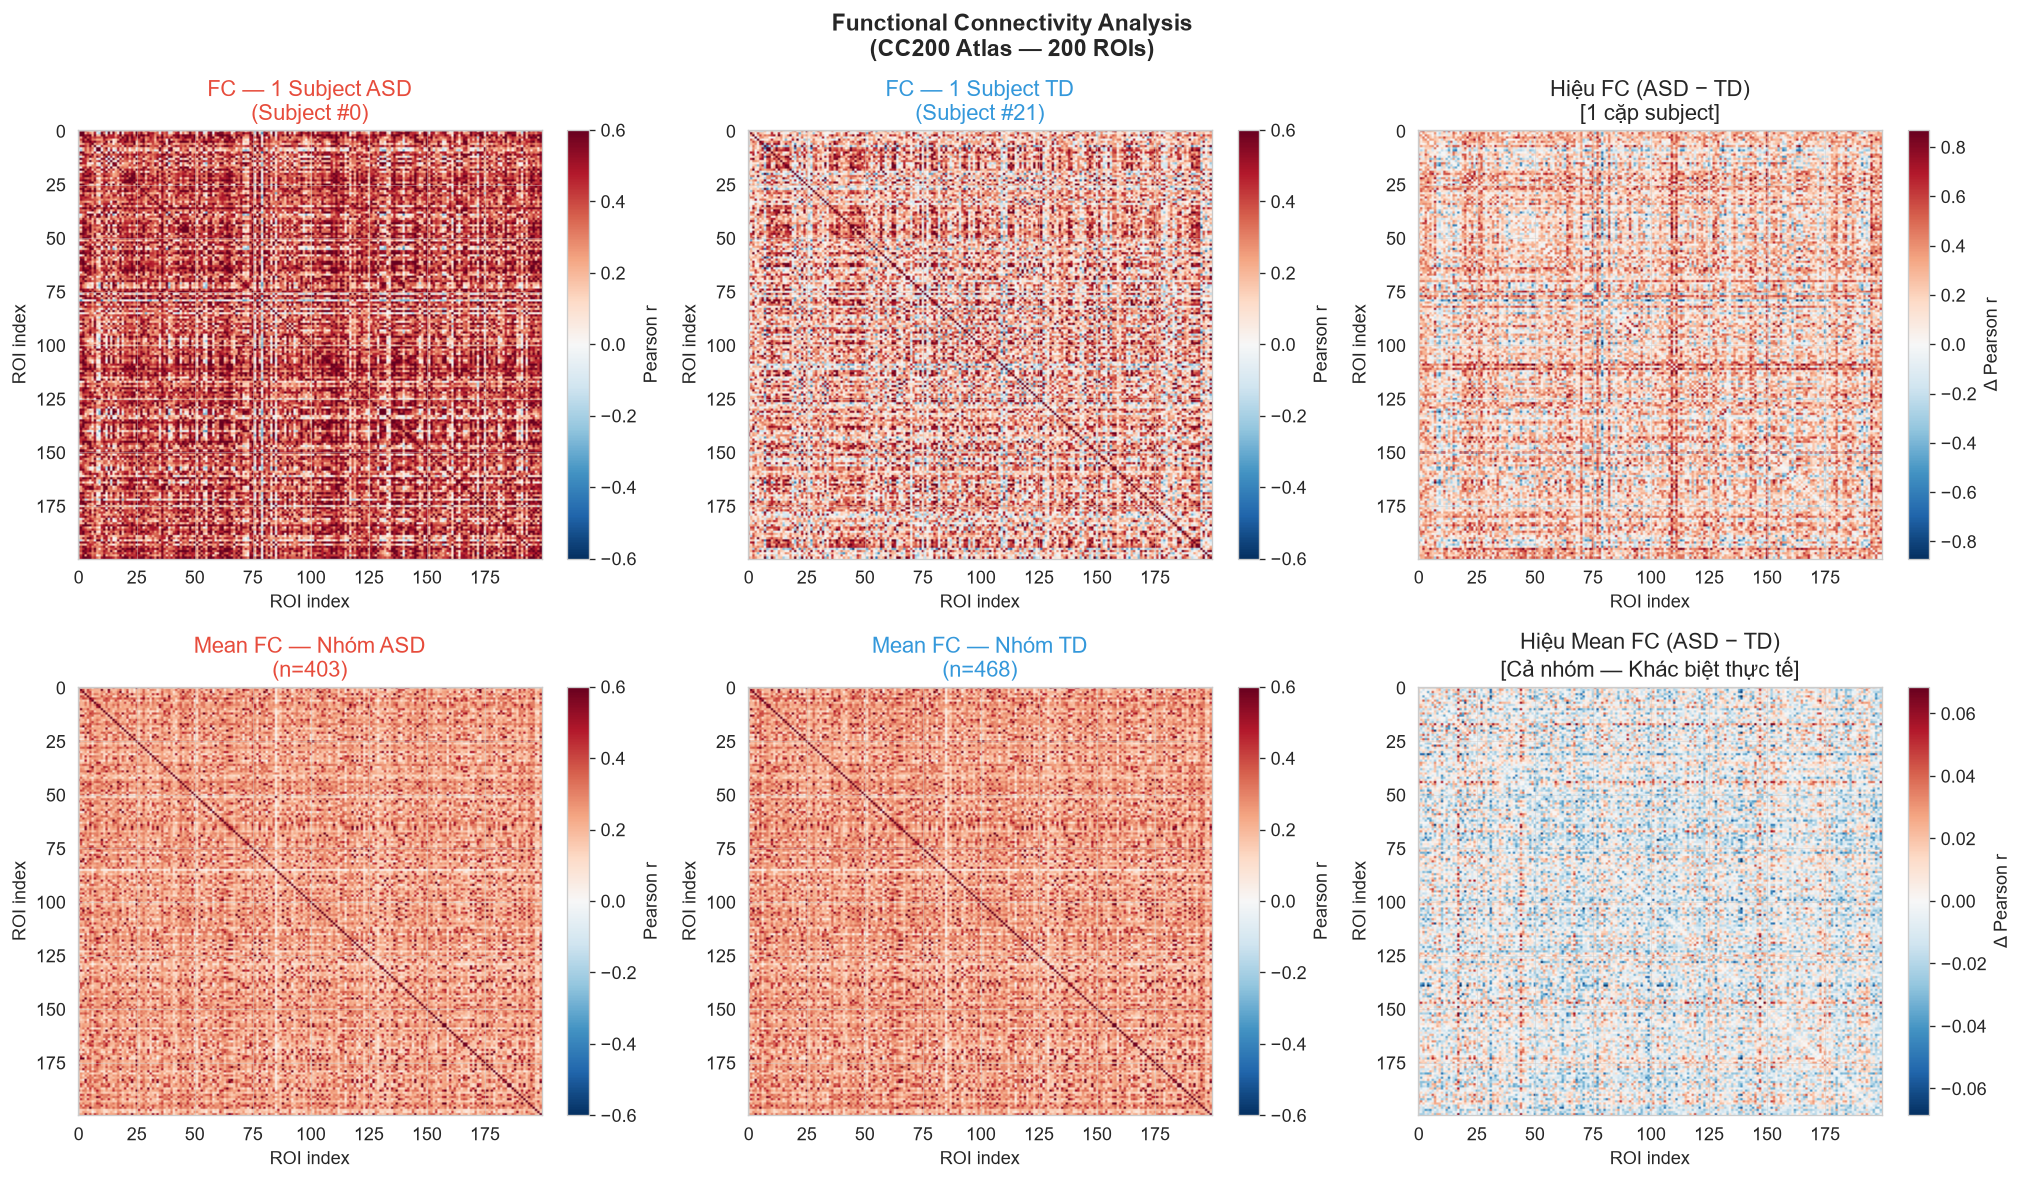

✅ Lưu: 03_fc_matrices.png

💡 Đọc ảnh hàng 2, cột phải (Hiệu Mean FC):
   → Đỏ đậm: kết nối mà ASD có FC cao hơn TD (overconnectivity)
   → Xanh đậm: kết nối mà TD có FC cao hơn ASD (underconnectivity)
   → Đây là bằng chứng trực quan về sự khác biệt FC giữa 2 nhóm


In [6]:
# Tính FC trung bình cho nhóm ASD và TD
mean_fc_asd = fc_matrices[y == 1].mean(axis=0)
mean_fc_td  = fc_matrices[y == 0].mean(axis=0)
diff_fc     = mean_fc_asd - mean_fc_td   # Hiệu: ASD - TD

fig, axes = plt.subplots(2, 3, figsize=(17, 10))
fig.suptitle('Functional Connectivity Analysis\n(CC200 Atlas — 200 ROIs)', fontsize=14, fontweight='bold')

vmax = 0.6

# ── Hàng 1: FC matrix của 1 subject đơn lẻ ──
im0 = axes[0,0].imshow(fc_matrices[idx_asd], cmap='RdBu_r', vmin=-vmax, vmax=vmax, aspect='auto')
axes[0,0].set_title(f'FC — 1 Subject ASD\n(Subject #{idx_asd})', color=COLORS['ASD'])
axes[0,0].set_xlabel('ROI index'); axes[0,0].set_ylabel('ROI index')
plt.colorbar(im0, ax=axes[0,0], fraction=0.046, label='Pearson r')

im1 = axes[0,1].imshow(fc_matrices[idx_td], cmap='RdBu_r', vmin=-vmax, vmax=vmax, aspect='auto')
axes[0,1].set_title(f'FC — 1 Subject TD\n(Subject #{idx_td})', color=COLORS['TD'])
axes[0,1].set_xlabel('ROI index'); axes[0,1].set_ylabel('ROI index')
plt.colorbar(im1, ax=axes[0,1], fraction=0.046, label='Pearson r')

diff_single = fc_matrices[idx_asd] - fc_matrices[idx_td]
vd_s = np.abs(diff_single).max() * 0.8
im2 = axes[0,2].imshow(diff_single, cmap='RdBu_r', vmin=-vd_s, vmax=vd_s, aspect='auto')
axes[0,2].set_title('Hiệu FC (ASD − TD)\n[1 cặp subject]')
axes[0,2].set_xlabel('ROI index'); axes[0,2].set_ylabel('ROI index')
plt.colorbar(im2, ax=axes[0,2], fraction=0.046, label='Δ Pearson r')

# ── Hàng 2: FC trung bình nhóm ──
im3 = axes[1,0].imshow(mean_fc_asd, cmap='RdBu_r', vmin=-vmax, vmax=vmax, aspect='auto')
axes[1,0].set_title(f'Mean FC — Nhóm ASD\n(n={y.sum()})', color=COLORS['ASD'])
axes[1,0].set_xlabel('ROI index'); axes[1,0].set_ylabel('ROI index')
plt.colorbar(im3, ax=axes[1,0], fraction=0.046, label='Pearson r')

im4 = axes[1,1].imshow(mean_fc_td, cmap='RdBu_r', vmin=-vmax, vmax=vmax, aspect='auto')
axes[1,1].set_title(f'Mean FC — Nhóm TD\n(n={(y==0).sum()})', color=COLORS['TD'])
axes[1,1].set_xlabel('ROI index'); axes[1,1].set_ylabel('ROI index')
plt.colorbar(im4, ax=axes[1,1], fraction=0.046, label='Pearson r')

vd = np.abs(diff_fc).max() * 0.8
im5 = axes[1,2].imshow(diff_fc, cmap='RdBu_r', vmin=-vd, vmax=vd, aspect='auto')
axes[1,2].set_title('Hiệu Mean FC (ASD − TD)\n[Cả nhóm — Khác biệt thực tế]')
axes[1,2].set_xlabel('ROI index'); axes[1,2].set_ylabel('ROI index')
plt.colorbar(im5, ax=axes[1,2], fraction=0.046, label='Δ Pearson r')

plt.tight_layout()
plt.savefig('03_fc_matrices.png', bbox_inches='tight')
plt.show()
print('✅ Lưu: 03_fc_matrices.png')
print('\n💡 Đọc ảnh hàng 2, cột phải (Hiệu Mean FC):')
print('   → Đỏ đậm: kết nối mà ASD có FC cao hơn TD (overconnectivity)')
print('   → Xanh đậm: kết nối mà TD có FC cao hơn ASD (underconnectivity)')
print('   → Đây là bằng chứng trực quan về sự khác biệt FC giữa 2 nhóm')

---
## 🔬 Cell 7 — Phân phối FC values và kiểm tra Feature

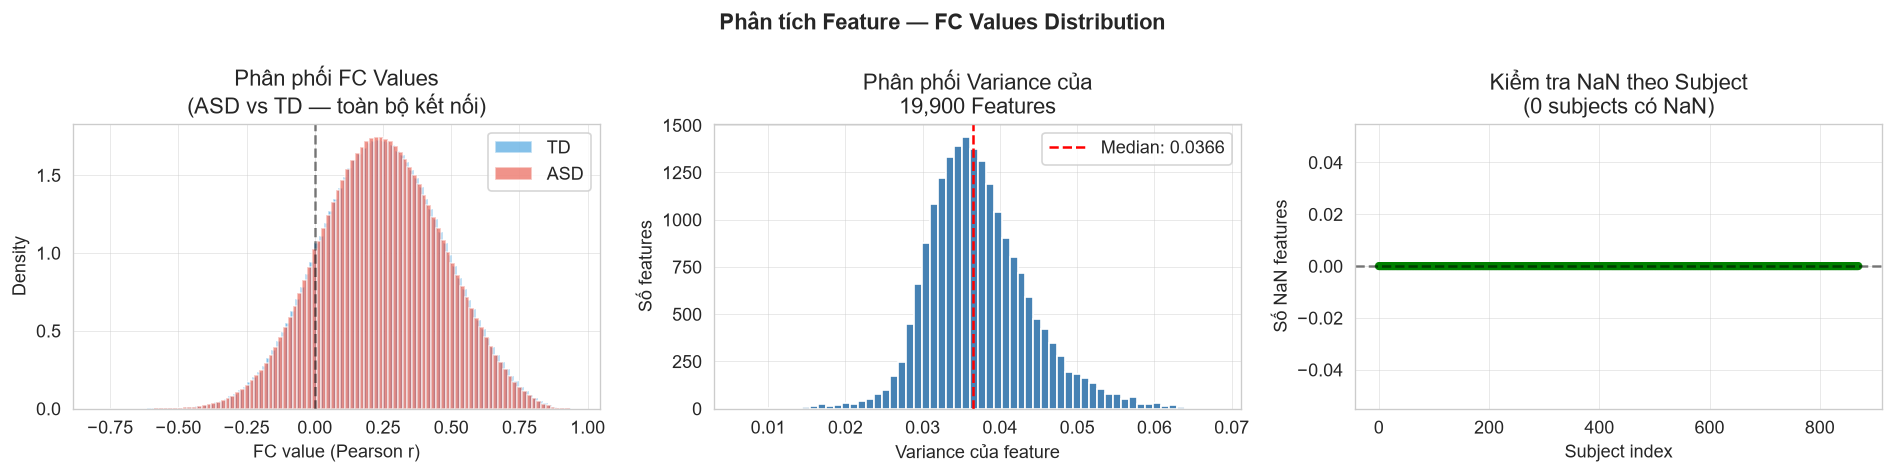

✅ Lưu: 04_feature_analysis.png

Summary Features:
  Shape X    : (871, 19900)
  FC range   : [-0.800, 0.958]
  NaN total  : 0


In [7]:
# Lấy upper triangle của tất cả FC matrices
idx_upper = np.triu_indices(200, k=1)
fc_asd_upper = fc_matrices[y == 1][:, idx_upper[0], idx_upper[1]].ravel()
fc_td_upper  = fc_matrices[y == 0][:, idx_upper[0], idx_upper[1]].ravel()

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
fig.suptitle('Phân tích Feature — FC Values Distribution', fontsize=13, fontweight='bold')

# ── [1] Histogram FC values ──
axes[0].hist(fc_td_upper,  bins=100, alpha=0.6, color=COLORS['TD'],  label='TD',  density=True)
axes[0].hist(fc_asd_upper, bins=100, alpha=0.6, color=COLORS['ASD'], label='ASD', density=True)
axes[0].set_xlabel('FC value (Pearson r)')
axes[0].set_ylabel('Density')
axes[0].set_title('Phân phối FC Values\n(ASD vs TD — toàn bộ kết nối)')
axes[0].legend()
axes[0].axvline(0, color='black', linestyle='--', alpha=0.5)

# ── [2] Feature variance ──
feature_var = X.var(axis=0)   # variance của từng feature
axes[1].hist(feature_var, bins=60, color='steelblue', edgecolor='white')
axes[1].set_xlabel('Variance của feature')
axes[1].set_ylabel('Số features')
axes[1].set_title('Phân phối Variance của\n19,900 Features')
axes[1].axvline(np.median(feature_var), color='red', linestyle='--',
                label=f'Median: {np.median(feature_var):.4f}')
axes[1].legend()

# ── [3] NaN check heatmap ──
nan_per_subject = np.isnan(X).sum(axis=1)
axes[2].scatter(range(len(nan_per_subject)), nan_per_subject,
                c=['red' if n > 0 else 'green' for n in nan_per_subject],
                s=15, alpha=0.7)
axes[2].set_xlabel('Subject index')
axes[2].set_ylabel('Số NaN features')
axes[2].set_title(f'Kiểm tra NaN theo Subject\n({(nan_per_subject > 0).sum()} subjects có NaN)')
axes[2].axhline(0, color='black', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig('04_feature_analysis.png', bbox_inches='tight')
plt.show()
print('✅ Lưu: 04_feature_analysis.png')
print(f'\nSummary Features:')
print(f'  Shape X    : {X.shape}')
print(f'  FC range   : [{X.min():.3f}, {X.max():.3f}]')
print(f'  NaN total  : {np.isnan(X).sum()}')

---
## ✂️ Cell 8 — Chuẩn bị Data Split

**Chiến lược:** Tách 20% làm **test set cố định** (không dùng trong training). Phần còn lại (80%) dùng để **5-Fold Stratified CV**.

> ⚠️ **Lưu ý về leakage:** `StandardScaler` phải chỉ được `fit` trên tập train. Dùng `Pipeline` của sklearn để đảm bảo điều này tự động.

In [8]:
# # Xử lý NaN nếu có (điền bằng 0 — tức là không có kết nối)
# X_clean = np.nan_to_num(X, nan=0.0)
#
# # Split: 80% train+val, 20% test
# X_tv, X_test, y_tv, y_test = train_test_split(
#     X_clean, y,
#     test_size=0.2,
#     stratify=y,
#     random_state=42
# )
#
# print('='*50)
# print('DATA SPLIT')
# print('='*50)
# print(f'  Train + Val : {X_tv.shape[0]} subjects')
# print(f'    → ASD     : {y_tv.sum()}')
# print(f'    → TD      : {(y_tv == 0).sum()}')
# print(f'  Test (held-out): {X_test.shape[0]} subjects')
# print(f'    → ASD     : {y_test.sum()}')
# print(f'    → TD      : {(y_test == 0).sum()}')
# print()
# print(f'  ✅ Tỉ lệ ASD trong Train: {y_tv.mean()*100:.1f}% | Test: {y_test.mean()*100:.1f}%')
# print(f'  (stratify=y đảm bảo tỉ lệ giống nhau)')

## LOSO LOAD

In [9]:
# Xử lý NaN nếu có
X_clean = np.nan_to_num(X, nan=0.0)

# Split: 80% train+val, 20% test
X_tv, X_test, y_tv, y_test = train_test_split(
    X_clean, y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

# ✅ THÊM DÒNG NÀY: Split sites cùng index với X và y
sites_tv, sites_test = train_test_split(
    sites,
    test_size=0.2,
    stratify=y,
    random_state=42   # ← PHẢI cùng random_state để index đồng bộ
)

print(f'Sites trong Train+Val: {np.unique(sites_tv)}')
print(f'Số sites: {len(np.unique(sites_tv))}')

Sites trong Train+Val: ['CALTECH' 'CMU' 'KKI' 'LEUVEN_1' 'LEUVEN_2' 'MAX_MUN' 'NYU' 'OHSU' 'OLIN'
 'PITT' 'SBL' 'SDSU' 'STANFORD' 'TRINITY' 'UCLA_1' 'UCLA_2' 'UM_1' 'UM_2'
 'USM' 'YALE']
Số sites: 20


---
## 🤖 Cell 9 — Train SVM + 5-Fold Cross Validation

**Giải thích hyperparameter:**
- `kernel='linear'` → Vì số features (19,900) >> số samples (~871). Linear kernel ổn định và nhanh hơn RBF trong trường hợp này.
- `C=0.01` → Regularization mạnh → chống overfitting. Cần thử nhiều giá trị C qua GridSearch.
- `StandardScaler` → Chuẩn hóa features về mean=0, std=1 (bắt buộc cho SVM).

In [10]:
# import time
#
# # Định nghĩa Pipeline: Scale → SVM
# # Dùng Pipeline để đảm bảo scaler chỉ fit trên train fold (tránh leakage)
# svm_pipeline = Pipeline([
#     ('scaler', StandardScaler()),
#     ('svm',    SVC(kernel='linear', C=0.01, probability=True, random_state=42))
# ])
#
# # 5-Fold Stratified Cross Validation
# cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
#
# print('Đang chạy 5-Fold Cross Validation (sử dụng toàn bộ CPU)...')
# t0 = time.time()
#
# cv_results_site = cross_validate(
#     svm_pipeline, X_tv, y_tv,
#     cv=cv,
#     scoring=['accuracy', 'roc_auc', 'f1', 'balanced_accuracy'],
#     return_train_score=True,
#     n_jobs=-1
# )
#
# elapsed = time.time() - t0
# print(f'✅ Xong! Thời gian: {elapsed:.1f} giây\n')
#
# print('='*55)
# print('   5-FOLD CROSS VALIDATION RESULTS (Train+Val set)')
# print('='*55)
# metrics = [
#     ('Accuracy',          'accuracy'),
#     ('Balanced Accuracy', 'balanced_accuracy'),
#     ('AUC-ROC',           'roc_auc'),
#     ('F1-Score',          'f1'),
# ]
# for name, key in metrics:
#     test_vals  = cv_results_site[f'test_{key}']
#     train_vals = cv_results_site[f'train_{key}']
#     print(f'  {name:<22}: {test_vals.mean()*100:5.2f}% ± {test_vals.std()*100:.2f}%')
#     print(f'  {"(train)":<22}: {train_vals.mean()*100:5.2f}% ± {train_vals.std()*100:.2f}%')
#     gap = train_vals.mean() - test_vals.mean()
#     overfit_warning = '⚠️ (overfitting?)' if gap > 0.1 else '✅'
#     print(f'  {"Gap train-val":<22}: {gap*100:.2f}% {overfit_warning}\n')

## Using LOSO

In [11]:
import time
from sklearn.model_selection import LeaveOneGroupOut, GroupKFold


# Định nghĩa Pipeline: Scale → SVM
# Dùng Pipeline để đảm bảo scaler chỉ fit trên train fold (tránh leakage)
svm_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('svm',    SVC(kernel='linear', C=0.01, probability=True, random_state=42))
])


logo = LeaveOneGroupOut()

t0 = time.time()


cv_results_site_site = cross_validate(
    svm_pipeline, X_tv, y_tv,
    groups=sites_tv,
    cv=logo,
    scoring=['balanced_accuracy', 'roc_auc'],
    return_train_score=True
)


elapsed = time.time() - t0
print(f'✅ Xong! Thời gian: {elapsed:.1f} giây\n')

print('='*55)
print('   5-FOLD CROSS VALIDATION RESULTS (Train+Val set)')
print('='*55)
metrics = [
    ('Accuracy','accuracy'),
    ('Balanced Accuracy', 'balanced_accuracy'),
    ('AUC-ROC','roc_auc'),
    ('F1-Score','f1'),
]
for name, key in metrics:
    test_vals  = cv_results_site_site[f'test_{key}']
    train_vals = cv_results_site_site[f'train_{key}']
    print(f'  {name:<22}: {test_vals.mean()*100:5.2f}% ± {test_vals.std()*100:.2f}%')
    print(f'  {"(train)":<22}: {train_vals.mean()*100:5.2f}% ± {train_vals.std()*100:.2f}%')
    gap = train_vals.mean() - test_vals.mean()
    overfit_warning = '⚠️ (overfitting?)' if gap > 0.1 else '✅'
    print(f'  {"Gap train-val":<22}: {gap*100:.2f}% {overfit_warning}\n')

Đang chạy 5-Fold Cross Validation (sử dụng toàn bộ CPU)...
✅ Xong! Thời gian: 8810.9 giây

   5-FOLD CROSS VALIDATION RESULTS (Train+Val set)


KeyError: 'test_accuracy'

---
## 📉 Cell 10 — Visualize Cross Validation Results

KeyError: 'train_accuracy'

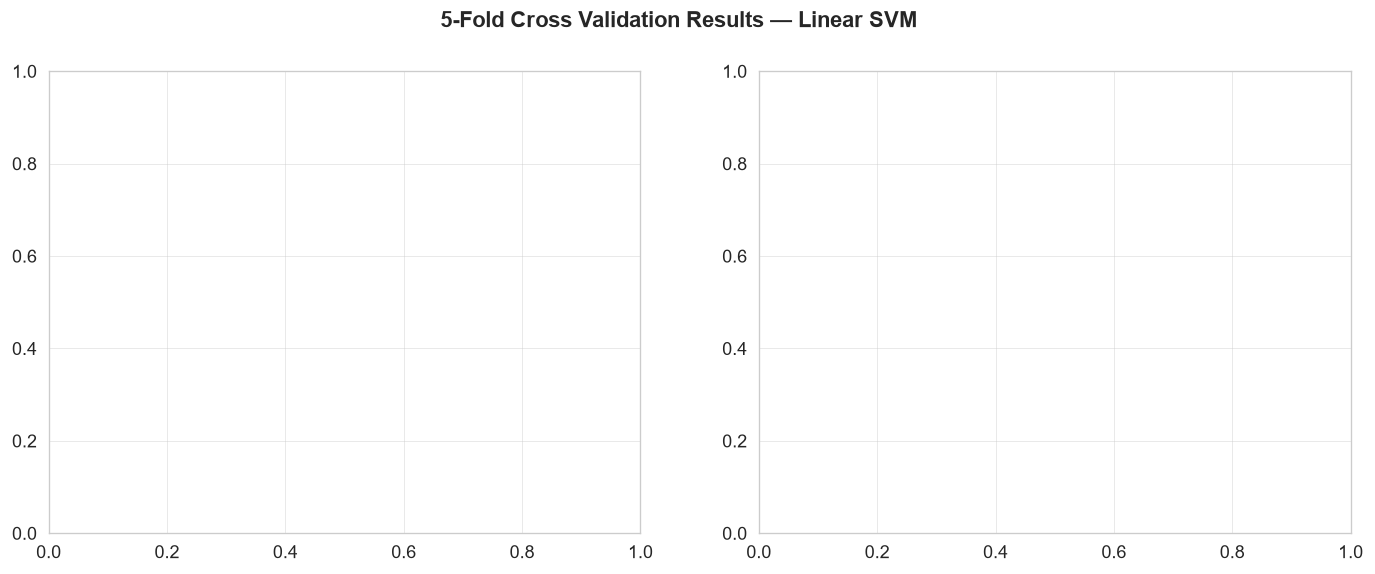

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('5-Fold Cross Validation Results — Linear SVM', fontsize=13, fontweight='bold')

# ── [1] Accuracy theo từng fold ──
folds = [f'Fold {i+1}' for i in range(5)]
train_acc = cv_results_site_site['train_accuracy'] * 100
test_acc  = cv_results_site_site['test_accuracy']  * 100

x = np.arange(5)
w = 0.35
axes[0].bar(x - w/2, train_acc, w, label='Train Accuracy', color='steelblue', alpha=0.8)
axes[0].bar(x + w/2, test_acc,  w, label='Val Accuracy',   color='orange',    alpha=0.8)
for i, (tr, te) in enumerate(zip(train_acc, test_acc)):
    axes[0].text(i - w/2, tr + 0.3, f'{tr:.1f}', ha='center', fontsize=8)
    axes[0].text(i + w/2, te + 0.3, f'{te:.1f}', ha='center', fontsize=8)
axes[0].set_xticks(x)
axes[0].set_xticklabels(folds)
axes[0].set_ylabel('Accuracy (%)')
axes[0].set_title('Accuracy theo từng Fold')
axes[0].set_ylim(40, 100)
axes[0].legend()
axes[0].axhline(test_acc.mean(), color='red', linestyle='--', alpha=0.7,
                label=f'Mean Val: {test_acc.mean():.1f}%')

# ── [2] Tất cả metrics ──
metric_names = ['Accuracy', 'Balanced\nAccuracy', 'AUC-ROC', 'F1-Score']
metric_keys  = ['accuracy', 'balanced_accuracy', 'roc_auc', 'f1']
means = [cv_results_site_site[f'test_{k}'].mean() * 100 for k in metric_keys]
stds  = [cv_results_site_site[f'test_{k}'].std()  * 100 for k in metric_keys]

bars = axes[1].bar(metric_names, means, color=['#3498DB','#2ECC71','#E67E22','#9B59B6'],
                   width=0.5, alpha=0.85, edgecolor='white')
axes[1].errorbar(metric_names, means, yerr=stds, fmt='none',
                 color='black', capsize=5, linewidth=2)
for bar, mean, std in zip(bars, means, stds):
    axes[1].text(bar.get_x() + bar.get_width()/2,
                 mean + std + 0.5,
                 f'{mean:.1f}±{std:.1f}%',
                 ha='center', fontsize=9, fontweight='bold')
axes[1].set_ylabel('Score (%)')
axes[1].set_title('Tất cả Metrics (Mean ± Std)')
axes[1].set_ylim(40, 105)
axes[1].axhline(50, color='gray', linestyle='--', alpha=0.5, label='Random baseline (50%)')
axes[1].legend()

plt.tight_layout()
plt.savefig('05_cv_results_site.png', bbox_inches='tight')
plt.show()
print('✅ Lưu: 05_cv_results_site.png')

---
## 🏁 Cell 11 — Đánh giá Final trên Test Set (Held-out)

> **Quan trọng:** Cell này chỉ chạy **một lần duy nhất** sau khi đã chọn xong model và hyperparameter. Không được dùng kết quả test set để điều chỉnh model.

In [13]:
# Train lại trên toàn bộ Train+Val set
svm_pipeline.fit(X_tv, y_tv)

# Dự đoán trên Test set
y_pred = svm_pipeline.predict(X_test)
y_prob = svm_pipeline.predict_proba(X_test)[:, 1]   # xác suất thuộc class ASD

print('='*55)
print('   FINAL TEST SET RESULTS (Held-out 20%)')
print('='*55)
print(f'  Accuracy          : {accuracy_score(y_test, y_pred)*100:.2f}%')
print(f'  Balanced Accuracy : {__import__("sklearn.metrics", fromlist=["balanced_accuracy_score"]).balanced_accuracy_score(y_test, y_pred)*100:.2f}%')
print(f'  AUC-ROC           : {roc_auc_score(y_test, y_prob):.4f}')
print(f'  F1-Score (ASD)    : {f1_score(y_test, y_pred):.4f}')
print()
print('Detailed Classification Report:')
print(classification_report(y_test, y_pred, target_names=['TD (0)', 'ASD (1)']))

   FINAL TEST SET RESULTS (Held-out 20%)
  Accuracy          : 72.57%
  Balanced Accuracy : 72.42%
  AUC-ROC           : 0.7771
  F1-Score (ASD)    : 0.7037

Detailed Classification Report:
              precision    recall  f1-score   support

      TD (0)       0.74      0.74      0.74        94
     ASD (1)       0.70      0.70      0.70        81

    accuracy                           0.73       175
   macro avg       0.72      0.72      0.72       175
weighted avg       0.73      0.73      0.73       175



---
## 📊 Cell 12 — Visualize Final Results (Confusion Matrix + ROC Curve)

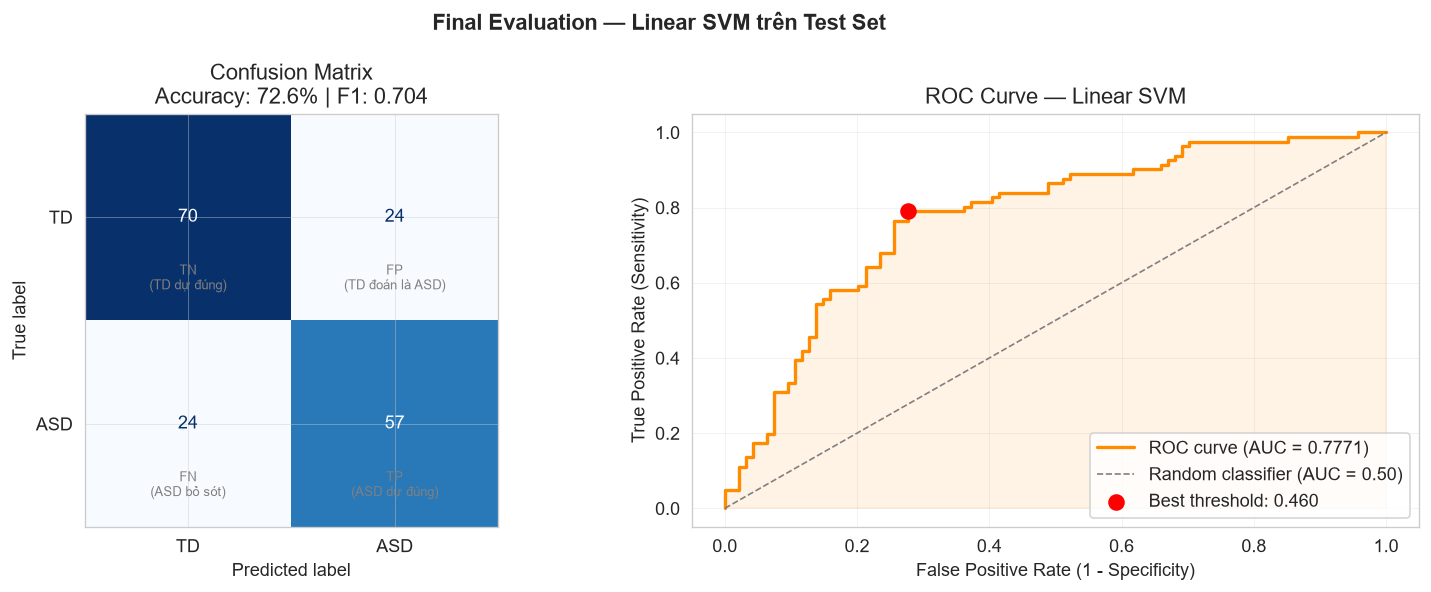

✅ Lưu: 06_final_results.png


In [14]:
from sklearn.metrics import balanced_accuracy_score

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fig.suptitle('Final Evaluation — Linear SVM trên Test Set', fontsize=13, fontweight='bold')

# ── [1] Confusion Matrix ──
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['TD', 'ASD'])
disp.plot(ax=axes[0], cmap='Blues', colorbar=False)
axes[0].set_title(
    f'Confusion Matrix\n'
    f'Accuracy: {accuracy_score(y_test, y_pred)*100:.1f}% | '
    f'F1: {f1_score(y_test, y_pred):.3f}'
)

# Thêm nhãn TP/FP/FN/TN
labels = [['TN\n(TD dự đúng)', 'FP\n(TD đoán là ASD)'],
          ['FN\n(ASD bỏ sót)', 'TP\n(ASD dự đúng)']]
for i in range(2):
    for j in range(2):
        axes[0].text(j, i + 0.35, labels[i][j], ha='center',
                     fontsize=8, color='gray')

# ── [2] ROC Curve ──
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
auc_val = roc_auc_score(y_test, y_prob)

axes[1].plot(fpr, tpr, color='darkorange', linewidth=2,
             label=f'ROC curve (AUC = {auc_val:.4f})')
axes[1].plot([0, 1], [0, 1], color='gray', linestyle='--', linewidth=1,
             label='Random classifier (AUC = 0.50)')
axes[1].fill_between(fpr, tpr, alpha=0.1, color='darkorange')
axes[1].set_xlabel('False Positive Rate (1 - Specificity)')
axes[1].set_ylabel('True Positive Rate (Sensitivity)')
axes[1].set_title('ROC Curve — Linear SVM')
axes[1].legend(loc='lower right')
axes[1].grid(alpha=0.3)

# Đánh dấu điểm threshold tốt nhất (Youden's J = TPR - FPR)
best_idx = np.argmax(tpr - fpr)
axes[1].scatter(fpr[best_idx], tpr[best_idx], color='red', s=80, zorder=5,
                label=f'Best threshold: {thresholds[best_idx]:.3f}')
axes[1].legend(loc='lower right')

plt.tight_layout()
plt.savefig('06_final_results.png', bbox_inches='tight')
plt.show()
print('✅ Lưu: 06_final_results.png')

---
## 🔍 Cell 13 — Top Connections quan trọng nhất (Feature Importance)

**Giải thích:**  
Linear SVM có `coef_` — hệ số trọng số cho mỗi feature. `|coef_|` lớn = feature đó quan trọng hơn trong quyết định phân loại. Đây là bước **XAI sơ bộ** cho SVM.

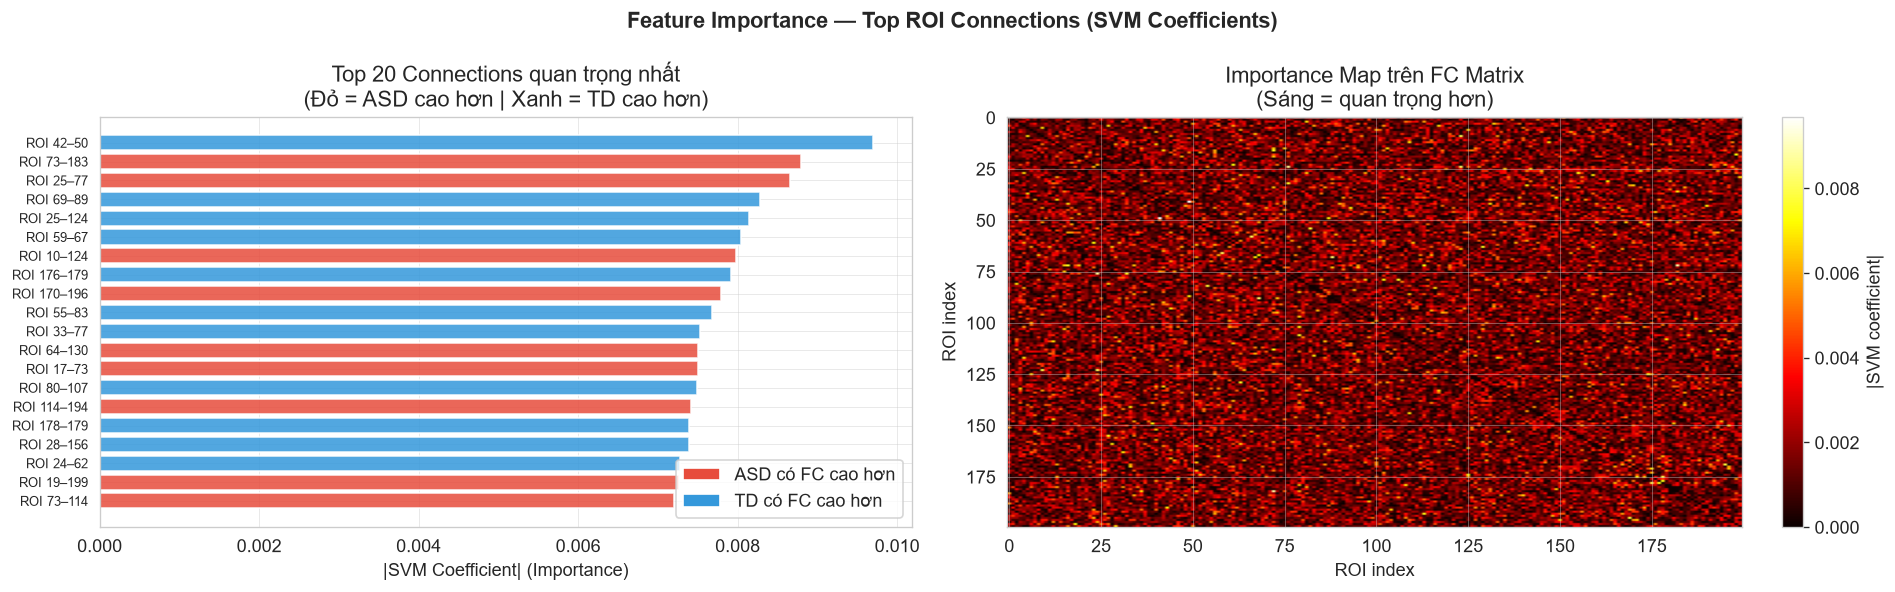

✅ Lưu: 07_feature_importance.png

Top 5 connections quan trọng nhất:
  #1: ROI 42–ROI 50 | importance=0.0097 | TD cao hơn
  #2: ROI 73–ROI 183 | importance=0.0088 | ASD cao hơn
  #3: ROI 25–ROI 77 | importance=0.0087 | ASD cao hơn
  #4: ROI 69–ROI 89 | importance=0.0083 | TD cao hơn
  #5: ROI 25–ROI 124 | importance=0.0081 | TD cao hơn


In [15]:
# Lấy hệ số SVM (đã scale)
svm_coef = svm_pipeline.named_steps['svm'].coef_[0]   # shape: (19900,)
importance = np.abs(svm_coef)   # giá trị tuyệt đối = mức độ quan trọng

# Map feature index → (ROI_i, ROI_j)
idx_i, idx_j = np.triu_indices(200, k=1)

# Top 20 features quan trọng nhất
top_n = 20
top_idx = np.argsort(importance)[::-1][:top_n]

top_importance = importance[top_idx]
top_roi_pairs  = [(idx_i[i]+1, idx_j[i]+1) for i in top_idx]   # 1-indexed
top_coef_sign  = np.sign(svm_coef[top_idx])   # dương = ASD cao hơn, âm = TD cao hơn

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
fig.suptitle('Feature Importance — Top ROI Connections (SVM Coefficients)',
             fontsize=13, fontweight='bold')

# ── [1] Bar chart Top 20 ──
bar_colors = [COLORS['ASD'] if s > 0 else COLORS['TD'] for s in top_coef_sign]
y_labels   = [f'ROI {a}–{b}' for a, b in top_roi_pairs]

axes[0].barh(range(top_n)[::-1], top_importance,
             color=bar_colors, alpha=0.85, edgecolor='white')
axes[0].set_yticks(range(top_n))
axes[0].set_yticklabels(y_labels[::-1], fontsize=8)
axes[0].set_xlabel('|SVM Coefficient| (Importance)')
axes[0].set_title(f'Top {top_n} Connections quan trọng nhất\n'
                  '(Đỏ = ASD cao hơn | Xanh = TD cao hơn)')

# Legend
from matplotlib.patches import Patch
legend_elements = [Patch(facecolor=COLORS['ASD'], label='ASD có FC cao hơn'),
                   Patch(facecolor=COLORS['TD'],  label='TD có FC cao hơn')]
axes[0].legend(handles=legend_elements, loc='lower right')

# ── [2] Heatmap importance trên FC matrix ──
importance_matrix = np.zeros((200, 200))
for k, (i, j) in enumerate(zip(idx_i, idx_j)):
    importance_matrix[i, j] = importance[k]
    importance_matrix[j, i] = importance[k]   # symmetric

im = axes[1].imshow(importance_matrix, cmap='hot', aspect='auto')
axes[1].set_title('Importance Map trên FC Matrix\n(Sáng = quan trọng hơn)')
axes[1].set_xlabel('ROI index')
axes[1].set_ylabel('ROI index')
plt.colorbar(im, ax=axes[1], fraction=0.046, label='|SVM coefficient|')

plt.tight_layout()
plt.savefig('07_feature_importance.png', bbox_inches='tight')
plt.show()
print('✅ Lưu: 07_feature_importance.png')

print(f'\nTop 5 connections quan trọng nhất:')
for rank, (feat_idx, roi_pair, imp, sign) in enumerate(
    zip(top_idx[:5], top_roi_pairs[:5], top_importance[:5], top_coef_sign[:5])
):
    direction = 'ASD cao hơn' if sign > 0 else 'TD cao hơn'
    print(f'  #{rank+1}: ROI {roi_pair[0]}–ROI {roi_pair[1]} | importance={imp:.4f} | {direction}')

---
## 📋 Cell 14 — Tổng kết

Tóm tắt toàn bộ kết quả và danh sách ảnh output.

In [ ]:
from sklearn.metrics import balanced_accuracy_score

print('='*60)
print('   KẾT QUẢ CUỐI CÙNG — STANDARD LITERATURE PIPELINE')
print('='*60)
print()
print('Dataset:')
print(f'  ABIDE I (CPAC, BPF, no-GSR, CC200, QC)     ')
print(f'  Tổng subjects  : {len(y)}')
print(f'  Features       : {X.shape[1]:,} (FC upper triangle)')
print()
print('Model: Linear SVM (C=0.01) + StandardScaler')
print()
print('5-Fold CV (Train+Val set):')    
print(f'  Accuracy          : {cv_results_site["test_accuracy"].mean()*100:.2f}% ± {cv_results_site["test_accuracy"].std()*100:.2f}%')
print(f'  AUC-ROC           : {cv_results_site["test_roc_auc"].mean():.4f} ± {cv_results_site["test_roc_auc"].std():.4f}')
print(f'  F1-Score          : {cv_results_site["test_f1"].mean():.4f} ± {cv_results_site["test_f1"].std():.4f}')
print()
print('Final Test Set (Held-out 20%):')
print(f'  Accuracy          : {accuracy_score(y_test, y_pred)*100:.2f}%')
print(f'  Balanced Accuracy : {balanced_accuracy_score(y_test, y_pred)*100:.2f}%')
print(f'  AUC-ROC           : {roc_auc_score(y_test, y_prob):.4f}')
print(f'  F1-Score (ASD)    : {f1_score(y_test, y_pred):.4f}')
print()
print('Ảnh output đã tạo:')
outputs = [
    ('01_phenotypic_overview.png',  'Thống kê dataset: ASD/TD, tuổi, sites'),
    ('02_bold_timeseries.png',      'BOLD signal time series của các ROI'),
    ('03_fc_matrices.png',          'FC matrix: subject đơn lẻ & trung bình nhóm'),
    ('04_feature_analysis.png',     'Phân phối feature, variance, NaN check'),
    ('05_cv_results_site.png',           '5-Fold CV results theo từng fold và metric'),
    ('06_final_results.png',        'Confusion matrix & ROC curve (test set)'),
    ('07_feature_importance.png',   'Top connections quan trọng (SVM coef)'),
]
for fname, desc in outputs:
    print(f'  📄 {fname:<35} → {desc}')